<p style="text-align: center;"><span style="color: blue;"><strong><span style="font-size: x-large;">
    PROCESAMIENTO DE IMÁGENES DIGITALES</span></strong></span></p>

<p style="text-align: center;"><span style="color: blue;"><strong><span style="font-size: x-large;">PRÁCTICA 2: Ejercicios</span></strong></span></p>

In [3]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

### 📝 Ejercicio 1: Ruido sal y pimienta

Queremos cargar una imagen a color cualquiera (png), transformarla a escala de grises e introducirle ruido sal y pimienta. Una forma de hacerlo podría ser usando la herramienta ImageJ (se puede descargar en https://imagej.nih.gov/ij/): 

1. Carga una imagen a color y transfórmala a una imagen en escala de grises de 8 bits.
2. Añade ruido tipo sal y pimienta (Process->noise->salt and pepper) a la imagen en escala de grises y guárdala como imagen png.
3. Busca en la documentación y explica cómo exactamente se está añadiendo el ruido. 
>Pregunta: ¿Qué cantidad aproximada de píxeles de la imagen original se ven modificados por el ruido introducido?

La herramienta Salt and Pepper de ImageJ selecciona aleatoriamente un conjunto de píxeles a lo largo de la imagen y sustituye sus valores por los extremos de la escala de grises de 8 bits: $0$ (negro/pimienta) o $255$ (blanco/sal).

El algoritmo modifica aproximadamente un 5% de los píxeles totales de la imagen original ($2.5\%$ de ruido sal y $2.5\%$ de ruido pimienta).

### 📝 Ejercicio 2: Comparación entre cv.blur y cv.boxFilter

1. Carga una imagen en escala de grises y añádele ruido (puede ser gaussiano o impulsivo).
2. Aplica `cv.blur` y `cv.boxFilter` sobre la imagen ruidosa, usando el mismo tamaño de máscara en ambos casos.
3. Calcula la diferencia absoluta entre las dos imágenes resultantes (`cv.absdiff`).
4. Visualiza los resultados y compara.
5. Repite el mismo procedimiento con una imagen en color.
>Pregunta: ¿Qué diferencias observas entre `cv.blur` y `cv.boxFilter`?

In [15]:
# 1. Cargar imagen en escala de grises
img = cv.imread('FOTO-COCO-gris.tif', 0)


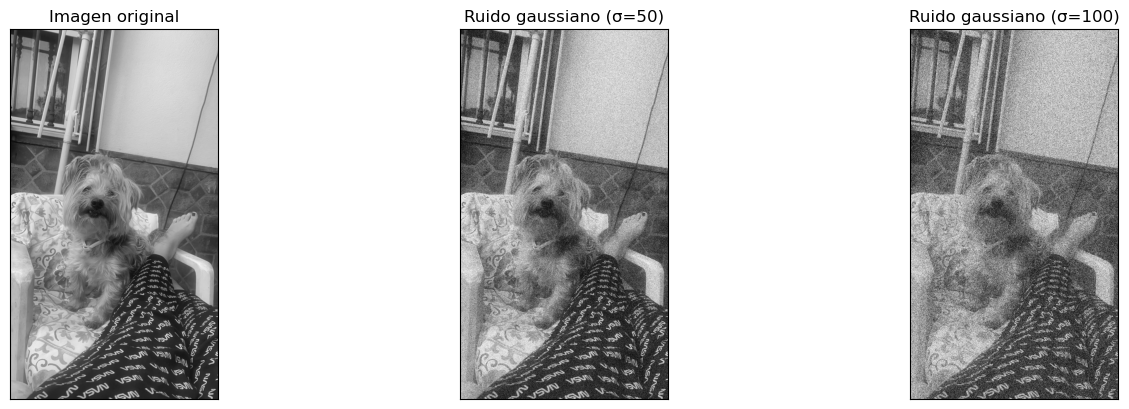

In [16]:
def ruido_gaussiano(image, mean=0, sigma=25):
    # Generamos una matriz de ruido del mismo tamaño que la imagen
    # con distribución normal (gaussiana)
    ruido = np.random.normal(mean, sigma, image.shape)
    
    # Añadimos el ruido a la imagen
    img_ruido = image + ruido
    
    # Aseguramos que los valores estén en el rango [0,255]
    img_ruido = np.clip(img_ruido, 0, 255)
    
    # Convertimos a uint8 para mantener el formato de imagen
    return np.uint8(img_ruido)

# Aplicamos diferentes niveles de ruido gaussiano
img_ruido_gauss1 = ruido_gaussiano(img, mean=0, sigma=50)  # Ruido suave
img_ruido_gauss2 = ruido_gaussiano(img, mean=0, sigma=100)  # Ruido más fuerte

# Mostramos los resultados
plt.subplots_adjust(left=None, bottom=None, right=2, top=None, wspace=0.5, hspace=0.5)

plt.subplot(1,3,1)
plt.title('Imagen original')
plt.xticks([]), plt.yticks([])
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,2)
plt.title('Ruido gaussiano (σ=50)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss1, cmap='gray', vmin=0, vmax=255)

plt.subplot(1,3,3)
plt.title('Ruido gaussiano (σ=100)')
plt.xticks([]), plt.yticks([])
plt.imshow(img_ruido_gauss2, cmap='gray', vmin=0, vmax=255)

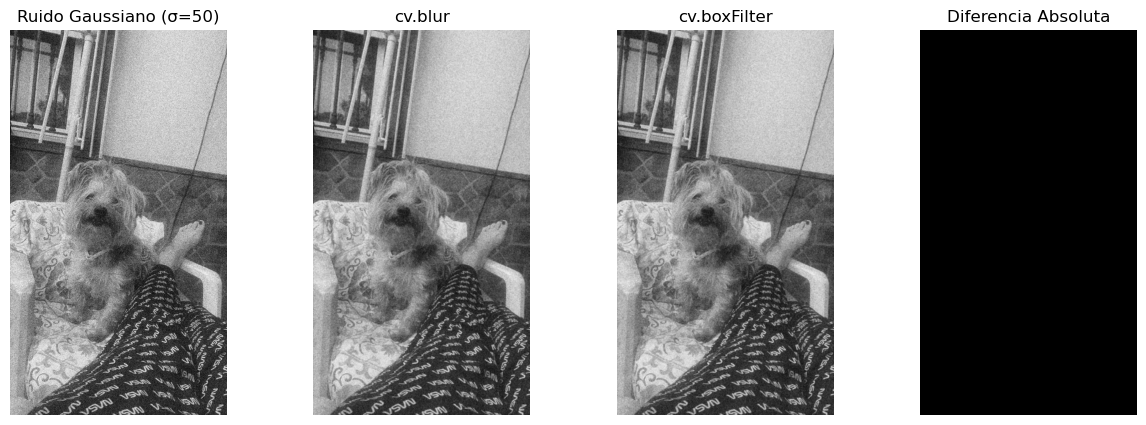

Suma total de diferencias: 0


In [17]:
# DIFERENCIA ENTRE cv.blur Y cv.boxFilter:
#
# - cv.blur(img, (k,k)): 
#   Calcula el PROMEDIO de los píxeles en la ventana (Suma / N). 
#   Mantiene el brillo original de la imagen mientras suaviza.
#
# - cv.boxFilter(img, ddepth, (k,k), normalize=True/False):
#   - Si normalize=True : Es idéntico a cv.blur (hace el promedio).
#   - Si normalize=False: SUMA los valores sin dividir. La imagen se aclara/satura 
#                         mucho porque acumula la intensidad total de la ventana.

# 2. Aplicar cv.blur y cv.boxFilter sobre la imagen con ruido gaussiano
ksize = (5, 5)
img_blur = cv.blur(img_ruido_gauss1, ksize)
img_box = cv.boxFilter(img_ruido_gauss1, -1, ksize, normalize=True)

# 3. Calcular la diferencia absoluta
diferencia = cv.absdiff(img_blur, img_box)

# 4. Visualizar los resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.title('Ruido Gaussiano (σ=50)')
plt.imshow(img_ruido_gauss1, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title('cv.blur')
plt.imshow(img_blur, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title('cv.boxFilter')
plt.imshow(img_box, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title('Diferencia Absoluta')
plt.imshow(diferencia, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

# Comprobación numérica
print("Suma total de diferencias:", np.sum(diferencia))



No existe ninguna diferencia entre cv.blur y cv.boxFilter cuando esta última se utiliza con la opción de normalización por defecto (normalize=True). Como se aprecia en la imagen de diferencia absoluta y en el valor numérico obtenido ($0$), ambas funciones aplican exactamente la misma operación de promediado espacial. La única diferencia práctica es que cv.boxFilter permite desactivar la normalización (normalize=False), mientras que cv.blur siempre aplica la media dividiendo entre el área del kernel. 

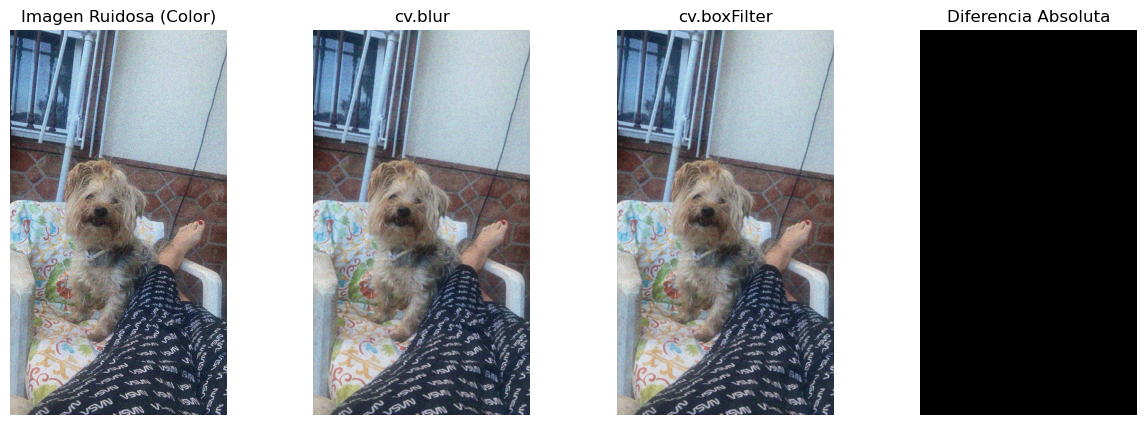

Suma total de diferencias en color: 0


In [24]:
# 5. Repetir el procedimiento con la imagen a color
img_color = cv.imread('FOTO-COCO-PNG.png') # Carga en BGR

# Generar ruido gaussiano en color
ruido = np.random.normal(0, 50, img_color.shape)
img_color_ruido = np.clip(img_color + ruido, 0, 255).astype(np.uint8)

# Aplicar filtros
ksize = (5, 5)
img_color_blur = cv.blur(img_color_ruido, ksize)
img_color_box = cv.boxFilter(img_color_ruido, -1, ksize, normalize=True)

# Calcular diferencia
diferencia_color = cv.absdiff(img_color_blur, img_color_box)

# Visualizar correctamente los colores BGR -> RGB
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.title('Imagen Ruidosa (Color)')
plt.imshow(cv.cvtColor(img_color_ruido, cv.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title('cv.blur')
plt.imshow(cv.cvtColor(img_color_blur, cv.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title('cv.boxFilter')
plt.imshow(cv.cvtColor(img_color_box, cv.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title('Diferencia Absoluta')
plt.imshow(cv.cvtColor(diferencia_color, cv.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

print("Suma total de diferencias en color:", np.sum(diferencia_color))

DIFERENCIAS IMAGEN EN ESCALA DE GRISES Y A COLOR
1. Número de canales procesados:

   - Escala de grises (1 canal): La convolución del kernel de $5 \times 5$ se ejecuta una sola vez sobre una única matriz de píxeles ($2\text{D}$).
   - Imagen a color (3 canales - BGR): OpenCV aplica el filtro 3 veces de forma independiente (una convolución por cada canal: Azul, Verde y Rojo) y luego vuelve a empaquetar los 3 canales en la imagen resultante.

3. Forma de la matriz (Shape)

   - En escala de grises la diferencia es un array 2D: (alto, ancho).
   - En color la diferencia es un array 3D: (alto, ancho, 3). La suma de diferencias en color evalúa $\vert{}B_1 - B_2\vert{} + \vert{}G_1 - G_2\vert{} + \vert{}R_1 - R_2\vert{}$ para cada píxel, resultando igualmente en $0$ porque la equivalencia entre cv.blur y cv.boxFilter se cumple independientemente en cada canal.

### 📝 Ejercicio 3:  Filtro Gaussiano y efecto de la σ

1.	Carga una imagen y añade ruido.
2.	Aplica el filtro `cv.GaussianBlur(image, ksize, sigma)` usando un tamaño de máscara fijo (por ejemplo, 5×5).
3.	Realiza dos pruebas variando el parámetro `sigma`:
    - Caso 1: `sigma` = 0 (OpenCV lo calcula automáticamente).
    - Caso 2: `sigma` = 2.
4.	Visualiza y compara los resultados.
>Pregunta: ¿El valor de sigma que calcula automáticamente OpenCV es mayor o menor que 2?


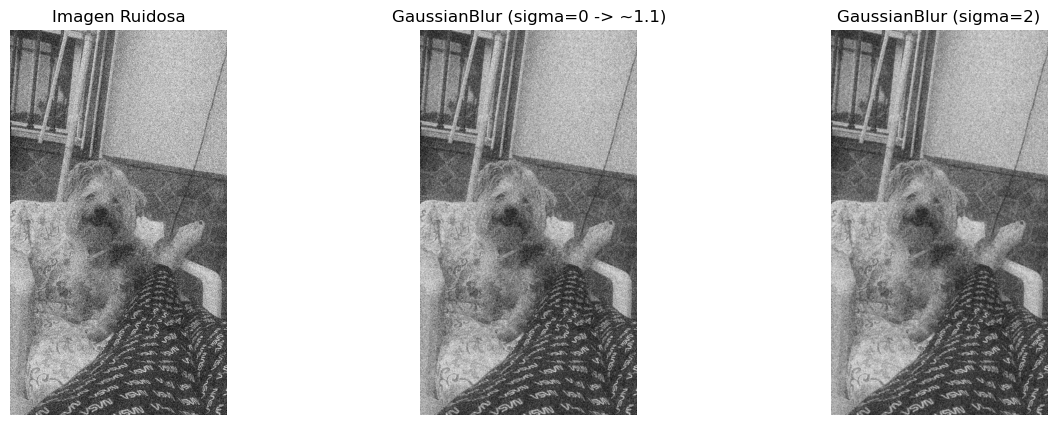

In [29]:
# FILTRO GAUSSIANO (cv2.GaussianBlur)
#
#    Aplica una media PONDERADA usando una campana de Gauss.
#    - Píxel central  -> Máximo peso (es el que más influye).
#    - Píxeles vecinos -> Van perdiendo importancia cuanto más lejos están del centro.
#
# PARÁMETROS PRINCIPALES:
#    - ksize (k, k) -> Tamaño de la ventana
#    - sigmaX       -> Anchura de la campana de Gauss. 
#                      * Valor pequeño: Desenfoque leve. el pixel del centro tiene casi todo el peso
#                      * Valor grande: Desenfoque fuerte.
#                      * Si es 0: OpenCV calcula el sigma óptimo automáticamente.

blur_gauss = cv2.GaussianBlur(img, (5, 5), sigmaX=0)

img = cv.imread('FOTO-COCO-PNG.png', 0)

def ruido_gaussiano(image, mean=0, sigma=25):
    ruido = np.random.normal(mean, sigma, image.shape)
    img_ruido = image + ruido
    img_ruido = np.clip(img_ruido, 0, 255)
    return np.uint8(img_ruido)


img_ruidosa = ruido_gaussiano(img, mean=0, sigma=100)  



ksize = (5, 5)
gauss_auto = cv.GaussianBlur(img_ruidosa, ksize, sigmaX=0)  # Caso 1: sigma = 0
gauss_sigma2 = cv.GaussianBlur(img_ruidosa, ksize, sigmaX=2) # Caso 2: sigma = 2



plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Imagen Ruidosa')
plt.imshow(img_ruidosa, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('GaussianBlur (sigma=0 -> ~1.1)')
plt.imshow(gauss_auto, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('GaussianBlur (sigma=2)')
plt.imshow(gauss_sigma2, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

In [30]:
dif_sigma = cv.absdiff(gauss_auto, gauss_sigma2)
print("Suma total de diferencias entre sigma=0 y sigma=2:", np.sum(dif_sigma))
print("Máxima diferencia en un solo píxel:", np.max(dif_sigma))

Suma total de diferencias entre sigma=0 y sigma=2: 19328613
Máxima diferencia en un solo píxel: 47


El valor de $\sigma$ que calcula automáticamente OpenCV para una máscara de $5 \times 5$ es menor que 2.   Aplicando la fórmula de OpenCV $\sigma = 0.3 \cdot ((k - 1)/2 - 1) + 0.8$ con $k = 5$, se obtiene un valor de $\sigma = 1.1$. Al comparar con $\sigma = 2$, un valor mayor distribuye un poco más de peso a los píxeles alejados del centro, aunque en una ventana tan pequeña como $5 \times 5$ el impacto visual sea casi imperceptible a simple vista.

### 📝 Ejercicio 4: Ruido sal y pimienta y filtro de eliminación

1. Carga una imagen en escala de grises.
2. Añade ruido de tipo sal y pimienta usando la siguiente función:

   def ruido(image, a, b):
   
            aleat = np.random.randint(1, 101, size=(image.shape[0], image.shape[1]))
   
            image2 = np.where(aleat <= 100*a, 0, image)      # ruido "sal"
   
            out = np.where(aleat > 100-100*b, 255, image2)   # ruido "pimienta"
   
            return out

Donde `a` y `b` controlan la cantidad de sal y pimienta respectivamente.

3.	Aplica diferentes filtros (media, mediana, gaussiano) e identifica cuál elimina mejor este tipo de ruido.
4.	Prueba con diferentes valores del parámetro a (a mayor valor, más ruido).
>Pregunta: ¿Cómo debe cambiar el tamaño de la máscara del filtro para poder eliminar más ruido?


In [34]:
img_gris = cv.imread('FOTO-COCO-gris.tif', 0)

In [35]:
def ruido(image, a, b):
     aleat = np.random.randint(1, 101, size=(image.shape[0], image.shape[1]))
     image2 = np.where(aleat <= 100*a, 0, image)      # ruido "sal"
     out = np.where(aleat > 100-100*b, 255, image2)   # ruido "pimienta"
     return out

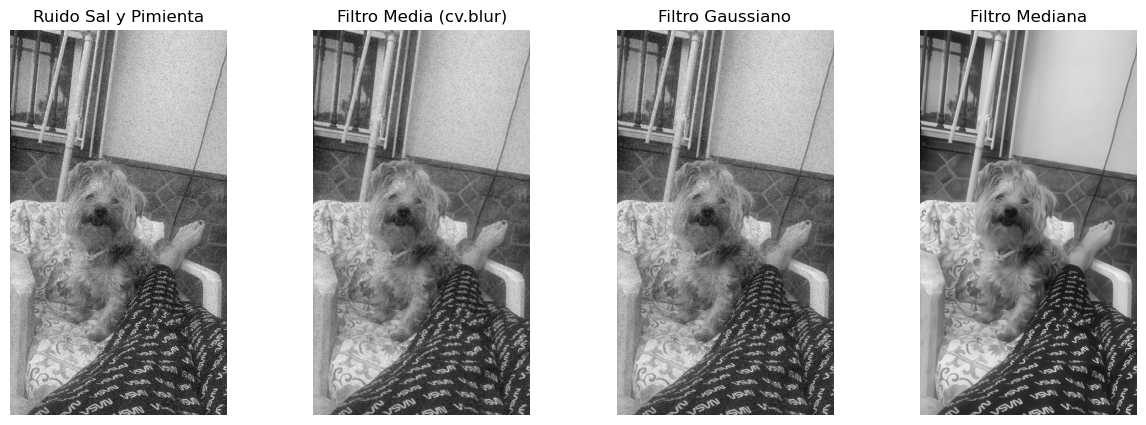

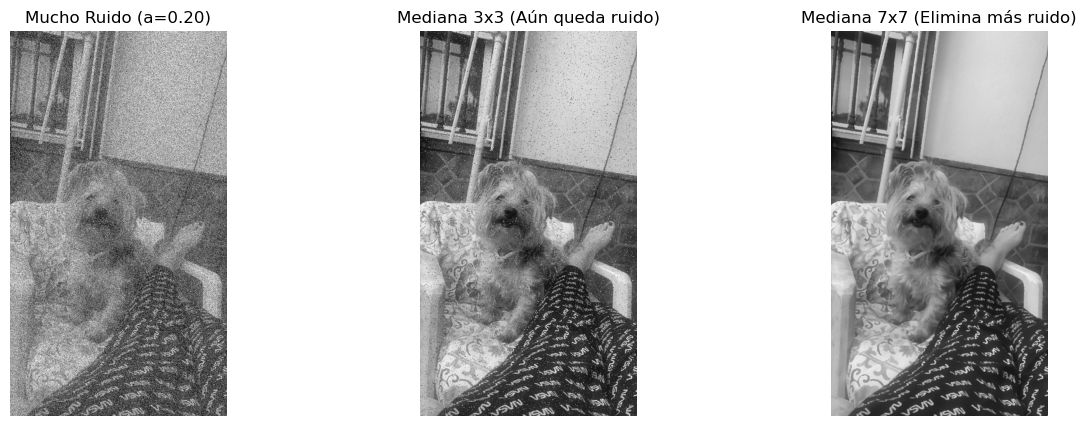

In [36]:
# Generar imagen con ruido (por ejemplo, 5% sal y 5% pimienta: a=0.05, b=0.05)
img_sp = ruido(img_gris, 0.05, 0.05)

# 3. Aplicar los tres tipos de filtros con kernel 5x5
f_media = cv.blur(img_sp, (5, 5))
f_gauss = cv.GaussianBlur(img_sp, (5, 5), 0)
f_mediana = cv.medianBlur(img_sp, 5)

# Visualizar comparación de filtros
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.title('Ruido Sal y Pimienta')
plt.imshow(img_sp, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title('Filtro Media (cv.blur)')
plt.imshow(f_media, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title('Filtro Gaussiano')
plt.imshow(f_gauss, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title('Filtro Mediana')
plt.imshow(f_mediana, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

# 4. Probar con mayor nivel de ruido (a mayor 'a', más ruido) y variar tamaño de máscara
img_mucho_ruido = ruido(img_gris, 0.20, 0.20)  # 20% sal y 20% pimienta

mediana_3x3 = cv.medianBlur(img_mucho_ruido, 3)
mediana_7x7 = cv.medianBlur(img_mucho_ruido, 7)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Mucho Ruido (a=0.20)')
plt.imshow(img_mucho_ruido, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Mediana 3x3 (Aún queda ruido)')
plt.imshow(mediana_3x3, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Mediana 7x7 (Elimina más ruido)')
plt.imshow(mediana_7x7, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

- Media (cv.blur): Suma todos los píxeles de la ventana y los divide entre el número total de píxeles.

- Gaussiano (cv.GaussianBlur): Pondera los píxeles dándole más importancia a los más cercanos al centro mediante la campana de Gauss.

- Mediana (cv.medianBlur): Ordena todos los valores de la ventana de menor a mayor y selecciona la mediana exacta.

El filtro de la mediana (cv.medianBlur) es el único eficaz para eliminar el ruido sal y pimienta. A diferencia de la media y el filtro gaussiano que promedian los valores extremales $0$ y $255$ emborronando la imagen, la mediana selecciona el valor central de la vecindad ordenada, descartando por completo los impulsos de ruido y preservando la nitidez de los bordes.

¿Cómo debe cambiar el tamaño de la máscara del filtro para poder eliminar más ruido?
El tamaño de la máscara debe aumentarse (por ejemplo, pasar de $3 \times 3$ a $5 \times 5$ o $7 \times 7$). Al incrementar la cantidad de ruido (valores más altos de $a$ y $b$), hay mayor probabilidad de encontrar varios píxeles ruidosos contiguos. Una máscara de mayor tamaño abarca un área con suficientes píxeles originales no contaminados, asegurando que la mediana calculada corresponda a la información real de la imagen. Como efecto colateral, un tamaño de máscara excesivamente grande puede suavizar ligeramente los detalles muy finos.

### 📝 Ejercicio 5: Estudio del parámetro ddepth en cv.Sobel

1.	Carga una imagen en escala de grises.
2.	Aplica el operador de Sobel (cv.Sobel) con diferentes valores del parámetro ddepth.
3.	Visualiza los resultados y compara.
> Pregunta: ¿Qué efecto tiene ddepth en la imagen resultante?


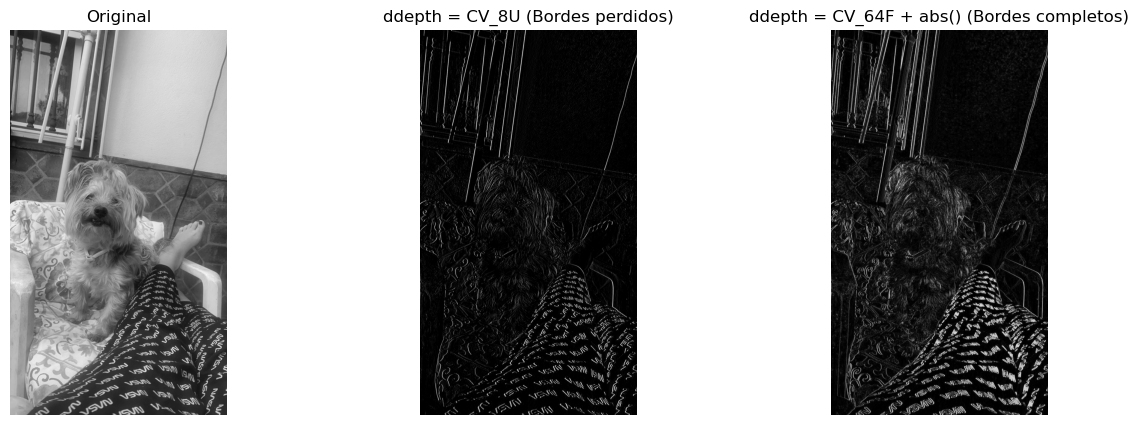

In [37]:
# 1. Cargar la imagen en escala de grises
img_gris = cv.imread('FOTO-COCO-gris.tif', 0)

# 2. Aplicar Sobel en dirección X (dx=1, dy=0) probando distintos valores de ddepth
# Caso A: Usando uint8 directo (cv.CV_8U) -> Trunca los gradientes negativos a 0
sobel_x_8u = cv.Sobel(img_gris, cv.CV_8U, 1, 0, ksize=3)

# Caso B: Usando float64 (cv.CV_64F) -> Mantiene bordes positivos y negativos
sobel_x_64f = cv.Sobel(img_gris, cv.CV_64F, 1, 0, ksize=3)

# Convertir el resultado en float64 de vuelta a uint8 tomando el valor absoluto (cv.convertScaleAbs)
sobel_x_abs = cv.convertScaleAbs(sobel_x_64f)

# 3. Visualizar y comparar resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Original')
plt.imshow(img_gris, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('ddepth = CV_8U (Bordes perdidos)')
plt.imshow(sobel_x_8u, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('ddepth = CV_64F + abs() (Bordes completos)')
plt.imshow(sobel_x_abs, cmap='gray')
plt.axis('off')

plt.show()

Sobel utiliza una pequeña matriz (kernel) que actúa como una resta rápida:$$\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$$Cuando este filtro pasa por la imagen, hace lo siguiente:

- Zona uniforme (sin bordes): Si todos los píxeles son iguales (por ejemplo, una pared blanca con valor $200$), la suma del filtro da 0 (negro total). No hay borde.
- Zona con un cambio brusco (un borde): Si a la izquierda hay un color oscuro ($10$) y a la derecha un color claro ($200$), la resta da un valor muy alto (un número grande). Ese píxel se pinta brillante. ¡Borde detectado!

En resumen Sobel sirve para detectar bordes porque compara los píxeles adyacentes para medir qué tan rápido cambia el color. Si no hay cambio, da cero; si el cambio es grande, resalta ese punto como un borde.


ddepth Sirve para evitar que la imagen pierda información de color o bordes al aplicar operaciones matemáticas.
Cuando usas OpenCV para aplicar filtros, restar imágenes o detectar bordes, el programa hace cálculos matemáticos píxel a píxel. ddepth sirve concretamente para:
- Evitar desbordamientos (Overflow): Si sumas dos imágenes normales (uint8), un píxel de $200 + 100 = 300$. Como el máximo normal es $255$, la imagen se rompe si no usas un ddepth de mayor capacidad como CV_16S o CV_64F.
- No perder valores negativos (Bordes): Al restar píxeles para buscar bordes, los resultados negativos pasan a ser $0$ (negro) si mantienes la imagen normal. Con ddepth = cv.CV_64F guardas esos negativos para no borrar la mitad de los bordes.
- Controlar la precisión: Te permite elegir si quieres una imagen rápida y ligera (CV_8U) o una con alta precisión decimal (CV_32F / CV_64F) para cálculos científicos o filtros complejos.

### 📝 Ejercicio 6: Estudio filtros en bordes y Laplaciano

1. Carga una imagen en escala de grises de 8 bits.
2. Busca la forma de aplicar un filtro creado por ti mismo a la imagen y averigua cuáles son las opciones con las que cuentas para el tratamiento del marco exterior de píxeles de la imagen. ¿Hay una opción por defecto? Haz pruebas.
3. Queremos realzar los detalles de la imagen usando el filtro Laplaciano. Averigua, consultando la documentación correspondiente, qué máscara está implementada y cómo está procesando la salida la implementación usada del Laplaciano, es decir ¿los valores de salida están ajustados a [0,255]? ¿O en qué rango están? ¿Qué ocurre con los valores negativos del Laplaciano? Según cómo sean estos valores de salida, razona cómo puedes usar ese Laplaciano para realzar los detalles claros de la imagen y hazlo, mostrando y evaluando los resultados tras haber probado con distintos tamaños de máscaras.  
Nota: si no “controlas” bien qué hace la implementación del Laplaciano, implementa tú mismo/a el filtro. 


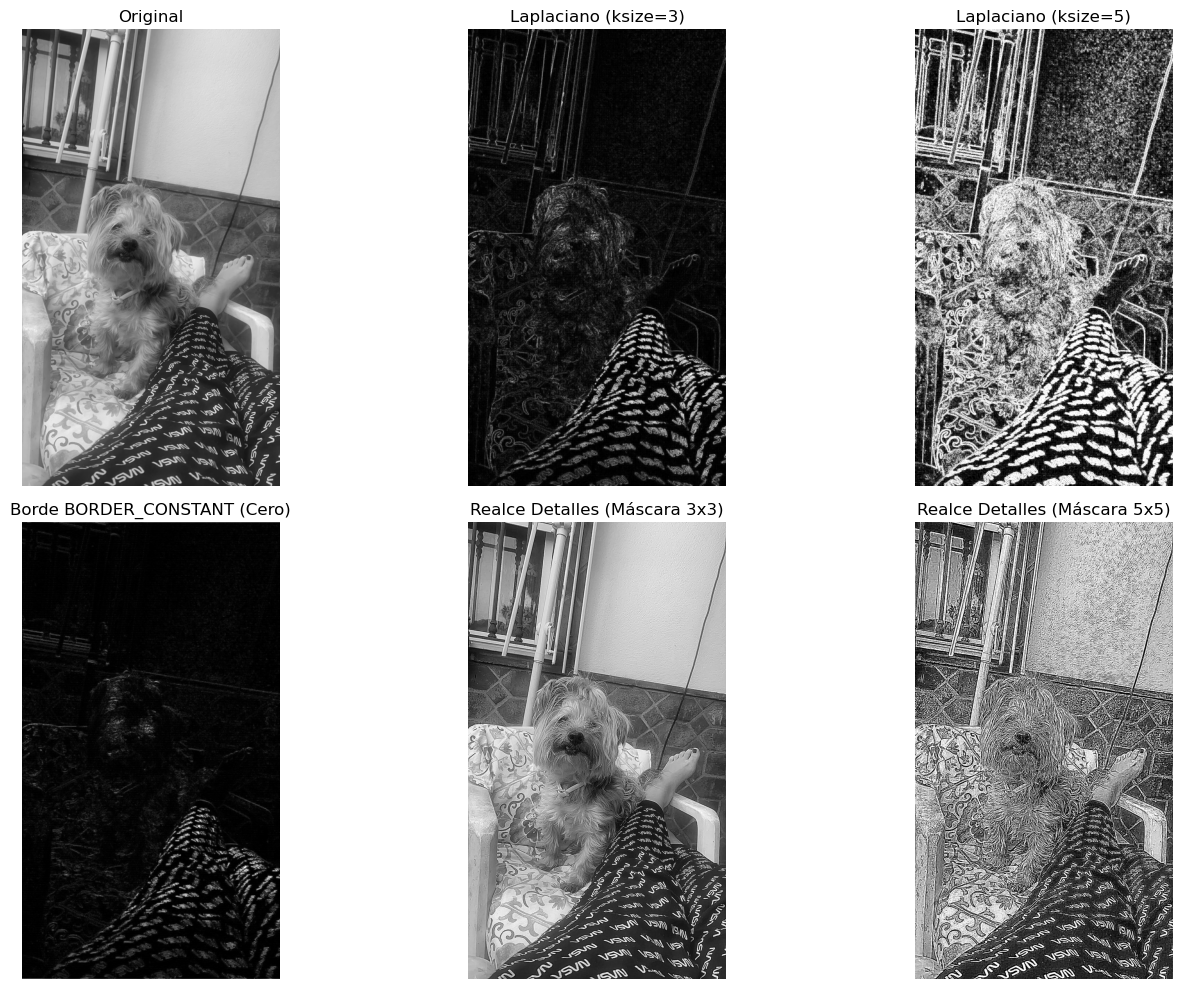

In [38]:
img_gris = cv.imread('FOTO-COCO-gris.tif', 0)

# ==========================================
# APARTADO 2: Filtro personalizado y bordes (cv.filter2D)
# ==========================================
# Creamos un filtro personalizado (ej. un detector de bordes horizontal simple)
kernel_custom = np.array([[-1, -1, -1],
                          [ 2,  2,  2],
                          [-1, -1, -1]], dtype=np.float32)

# Opciones de tratamiento de bordes en OpenCV:
# BORDER_DEFAULT (Reflect 101), BORDER_CONSTANT (rellena con 0), BORDER_REPLICATE
img_border_default = cv.filter2D(img_gris, cv.CV_64F, kernel_custom, borderType=cv.BORDER_DEFAULT)
img_border_constant = cv.filter2D(img_gris, cv.CV_64F, kernel_custom, borderType=cv.BORDER_CONSTANT)
img_border_replicate = cv.filter2D(img_gris, cv.CV_64F, kernel_custom, borderType=cv.BORDER_REPLICATE)

# ==========================================
# APARTADO 3: Laplaciano y Realce de detalles (Sharpening)
# ==========================================
# El Laplaciano mide la derivada segunda (cambios bruscos). 
# Para evitar truncar valores negativos, usamos ddepth = cv.CV_64F
laplaciano_3x3 = cv.Laplacian(img_gris, cv.CV_64F, ksize=3)
laplaciano_5x5 = cv.Laplacian(img_gris, cv.CV_64F, ksize=5)

# Para REALZAR los detalles (Sharpening), restamos el Laplaciano a la imagen original:
# Imagen_Realzada = Imagen_Original - Laplaciano
# Convertimos la imagen original a float64 para operar correctamente
img_float = img_gris.astype(np.float64)

realzada_3x3 = np.clip(img_float - laplaciano_3x3, 0, 255).astype(np.uint8)
realzada_5x5 = np.clip(img_float - laplaciano_5x5, 0, 255).astype(np.uint8)

# ==========================================
# VISUALIZACIÓN DE RESULTADOS
# ==========================================
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.title('Original')
plt.imshow(img_gris, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title('Laplaciano (ksize=3)')
plt.imshow(cv.convertScaleAbs(laplaciano_3x3), cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.title('Laplaciano (ksize=5)')
plt.imshow(cv.convertScaleAbs(laplaciano_5x5), cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.title('Borde BORDER_CONSTANT (Cero)')
plt.imshow(cv.convertScaleAbs(img_border_constant), cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title('Realce Detalles (Máscara 3x3)')
plt.imshow(realzada_3x3, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(2, 3, 6)
plt.title('Realce Detalles (Máscara 5x5)')
plt.imshow(realzada_5x5, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.tight_layout()
plt.show()

#### 1. Tratamiento del marco exterior (Bordes en `cv.filter2D`)
* **¿Cómo se aplica un filtro personalizado?** Mediante la función `cv.filter2D(src, ddepth, kernel, borderType)`.
* **Opciones de bordes disponibles:**
  * `BORDER_DEFAULT` (o `BORDER_REFLECT_101`): Refleja los píxeles del borde sin duplicar el extremo (`g f e | a b c d e f g | f e d`).
  * `BORDER_CONSTANT`: Rellena el marco exterior con un valor constante (por defecto $0$, negro).
  * `BORDER_REPLICATE`: Duplica los píxeles del borde hacia fuera (`a a a | a b c d e f g | g g g`).
* **Opción por defecto:** `cv.BORDER_DEFAULT` (`BORDER_REFLECT_101`).

2. Análisis del Filtro Laplaciano y Realce de Detalles

   Máscara implementada: Para $k=3$, OpenCV utiliza el kernel estándar de derivada segunda en 2D:$$\begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$$Rango de valores de salida y negativos: El resultado del Laplaciano no está ajustado a $[0, 255]$. Sus valores pueden ir desde números muy negativos hasta positivos grandes (aprox. $[-1020, 1020]$). Si se usa CV_8U, los valores negativos se recortan a $0$. Usando CV_64F preservamos los valores reales.

   ¿Cómo realzar los detalles?  Como el centro del kernel estándar del Laplaciano de OpenCV es negativo ($-4$), la derivada segunda resta brillo en los bordes. Para realzar los detalles y bordes claros de la imagen original, se debe restar el Laplaciano a la imagen original:$$\text{Imagen Realzada} = \text{Imagen Original} - \text{Laplaciano}$$Efecto según el tamaño de la máscara:
   - $3 \times 3$: Realza adecuadamente las líneas finas y bordes bien definidos sin sobrecargar la imagen.
   - $5 \times 5$ (o mayor): Realza bordes más gruesos, pero amplifica significativamente el ruido presente en la imagen y produce halos muy marcados en los contornos.